## Cross-Validation Analysis for Baby Joke Video Classification

This notebook provides a rigorous, publication-grade analysis of 10-fold cross-validation results across four architectures: `CNN-LSTM, 3D-CNN, Temporal Attention Network (TAN), and Multimodal (motion, facial, gesture)`. 
Based on the results of the models obtained after runing the complete pipeline.
It includes statistical comparisons, effect sizes, uncertainty quantification, efficiency trade-offs, and visualization. 

Package importation and configuration

In [1]:
import os
import json
import math
import itertools as it
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.stats import ttest_rel, friedmanchisquare, wilcoxon

import matplotlib.pyplot as plt
import seaborn as sns

# scikit_posthocs for advanced post-hoc tests (optional)
try:
    import scikit_posthocs as sp
    HAS_SCIKIT_POSTHOCS = True
except ImportError:
    HAS_SCIKIT_POSTHOCS = False
    print("Note: scikit_posthocs not available. Using alternative implementations.")

Note: scikit_posthocs not available. Using alternative implementations.


In [2]:
# Paths
RESULTS_CSV = '..' + '/outputs' + '/all_models_performance.csv'
ANALYSIS_DIR = '..' +  '/analysis'
FIG_DIR = '../figures'
OUT_DIR = '../outputs'
# If the directories do not exist, create them
# FIG_DIR.mkdir(parents=True, exist_ok=True) if not FIG_DIR.exists() else None
# OUT_DIR.mkdir(parents=True, exist_ok=True) if not OUT_DIR.exists() else None

In [3]:
# Plotting  style
sns.set(context='paper', style='whitegrid', font_scale=1.2)
COLORS = {
    'CNN_LSTM': '#8e44ad',
    '3D_CNN': '#e67e22',
    'TAN': '#16a085',
    'Multimodal': '#c0392b'
}

In [4]:
# Load and validate data
df = pd.read_csv(RESULTS_CSV)

In [5]:
# Standardize column names (if needed)
rename_map = {
    'model': 'model_name',
    'kappa_score': 'kappa',
}
df = df.rename(columns=rename_map)

In [6]:
expected_cols = [
    'model_name','fold','accuracy','precision','recall','f1_score','auc_roc','kappa',
    'train_loss','val_loss','test_loss','training_time','inference_time','timestamp'
]
missing = [c for c in expected_cols if c not in df.columns]
if missing:
    print('Warning: missing columns:', missing)

In [7]:
# Ensure folds are 1..10 per model
fold_counts = df.groupby('model_name')['fold'].nunique()
print('Unique folds per model:\n', fold_counts)

# Basic aggregates
metrics = ['accuracy','precision','recall','f1_score','kappa']
summary = df.groupby('model_name')[metrics].agg(['mean','std'])
summary.to_csv('../analysis/outputs/summary_by_model.csv')
summary

Unique folds per model:
 model_name
3D_CNN        10
CNN_LSTM      10
Multimodal    10
TAN           10
Name: fold, dtype: int64


accuracy           precision              recall            \
                mean       std      mean       std      mean       std   
model_name                                                               
3D_CNN      0.924473  0.028813  0.926300  0.028411  0.924473  0.028813   
CNN_LSTM    0.808126  0.050911  0.812794  0.049420  0.808126  0.050911   
Multimodal  0.947063  0.021670  0.949035  0.021701  0.947063  0.021670   
TAN         0.906832  0.038827  0.910259  0.036499  0.906832  0.038827   

            f1_score               kappa            
                mean       std      mean       std  
model_name                                          
3D_CNN      0.924301  0.028931  0.905585  0.036014  
CNN_LSTM    0.808002  0.050824  0.760141  0.063619  
Multimodal  0.946941  0.021792  0.933825  0.027094  
TAN         0.906569  0.039371  0.883529  0.048539

/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_69636/1013530633.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y='accuracy', palette=COLORS)


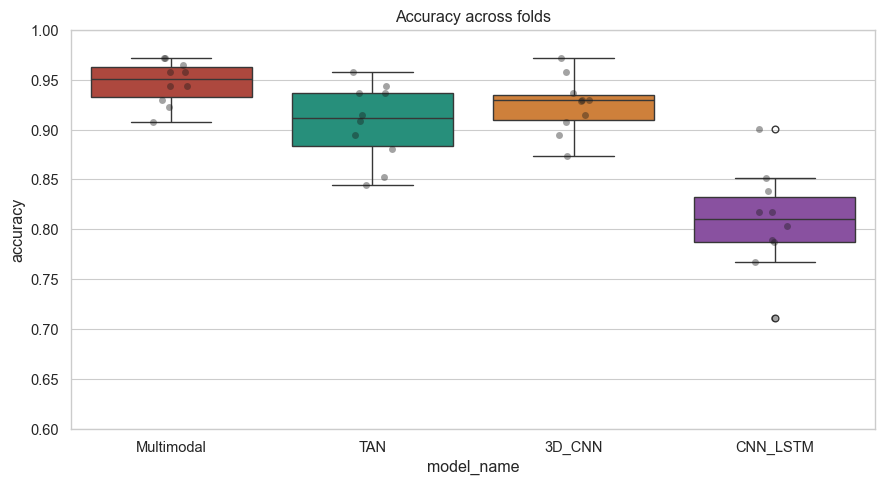

In [8]:
# Visualization: distributions and ranks
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='model_name', y='accuracy', palette=COLORS)
sns.stripplot(data=df, x='model_name', y='accuracy', color='k', alpha=0.4)
plt.ylim(0.6,1.0)
plt.title('Accuracy across folds')
plt.tight_layout()
plt.savefig('../analysis/figures/box_accuracy.png', dpi=200)
plt.show()

In [9]:
# Critical difference style ranks (per fold ranks lower=better)
ranks = df.copy()
ranks['rank'] = ranks.groupby('fold')['accuracy'].rank(ascending=False, method='average')
rank_summary = ranks.groupby('model_name')['rank'].agg(['mean','std']).sort_values('mean')
rank_summary.to_csv('../analysis/outputs/rank_summary.csv')
rank_summary

,mean,std
model_name,,
Multimodal,1.55,0.497214
3D_CNN,1.85,0.883491
TAN,2.70,0.823273
CNN_LSTM,3.90,0.316228


In [10]:
# Paired statistical tests: per-fold paired t-tests, correction
models = sorted(df['model_name'].unique())
pairs = list(it.combinations(models, 2))

In [11]:
results = []
for m1, m2 in pairs:
    a = df[df.model_name==m1].sort_values('fold')['accuracy'].values
    b = df[df.model_name==m2].sort_values('fold')['accuracy'].values
    # paired t-test
    tstat, pval = ttest_rel(a, b)
    # effect sizes
    d = (a - b)
    dz = d.mean() / (d.std(ddof=1) + 1e-12)  # Cohen's d_z for paired
    # Cliff's delta
    n = len(a)
    n_concord = sum((ai > bj) for ai in a for bj in b)
    n_discord = sum((ai < bj) for ai in a for bj in b)
    delta = (n_concord - n_discord) / (n*n)
    results.append({'m1': m1, 'm2': m2, 't': tstat, 'p_uncorrected': pval, 'cohen_dz': dz, 'cliffs_delta': delta})

In [12]:
res_df = pd.DataFrame(results)
# Holm-Bonferroni correction
res_df = res_df.sort_values('p_uncorrected').reset_index(drop=True)
K = len(res_df)
res_df['holm_threshold'] = [0.05/(K - i) for i in range(K)]
res_df['reject_h0'] = res_df['p_uncorrected'] < res_df['holm_threshold']
res_df.to_csv( '../analysis/outputs/paired_tests_accuracy.csv', index=False)
res_df

,m1,m2,t,p_uncorrected,cohen_dz,cliffs_delta,holm_threshold,reject_h0
0,CNN_LSTM,Multimodal,-7.956584,0.000023,-2.516093,-1.00,0.008333,True
1,3D_CNN,CNN_LSTM,5.260193,0.000521,1.663419,0.96,0.010000,True
2,CNN_LSTM,TAN,-4.491652,0.001507,-1.420385,-0.90,0.012500,True
3,Multimodal,TAN,3.137197,0.011982,0.992069,0.65,0.016667,True
4,3D_CNN,Multimodal,-1.816632,0.102650,-0.574470,-0.46,0.025000,False
5,3D_CNN,TAN,1.127109,0.288849,0.356423,0.19,0.050000,False


In [13]:
# Publication quality styling 

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150
mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['axes.titlesize'] = 12
mpl.rcParams['axes.labelsize'] = 11
mpl.rcParams['legend.fontsize'] = 10
mpl.rcParams['xtick.labelsize'] = 10
mpl.rcParams['ytick.labelsize'] = 10
palette = sns.color_palette('colorblind', 6)
COLORS = {
    'CNN_LSTM': palette[0],
    '3D_CNN': palette[1],
    'TAN': palette[2],
    'Multimodal': palette[3]
}

def finalize(ax, title=None, xlabel=None, ylabel=None, fname=None):
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.figure.tight_layout()
    if fname:
        ax.figure.savefig('../analysis/figures/' + fname, dpi=300, bbox_inches='tight')

In [14]:
# Robustness checks: fold alignment and counts
fold_counts = df.groupby('model_name')['fold'].nunique()
print('Folds per model:', fold_counts.to_dict())
assert fold_counts.nunique() == 1 and list(fold_counts)[0] == 10, 'Each model must have exactly 10 folds.'

Folds per model: {'3D_CNN': 10, 'CNN_LSTM': 10, 'Multimodal': 10, 'TAN': 10}


In [15]:
# Ensure fold indices align for paired tests
for f in sorted(df['fold'].unique()):
    models_here = set(df[df.fold==f]['model_name'])
    assert set(df['model_name'].unique()) <= models_here or models_here == set(df['model_name'].unique()), 'Missing model in fold %s' % f
print('Fold alignment checks passed.')

Fold alignment checks passed.


/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_69636/2587156730.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)
/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_69636/2587156730.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)
/var/folders/fp/nfh3jlt16mv7dm_xv5cq2c040000gn/T/ipykernel_69636/2587156730.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='model_name', y=metric, palette=COLO

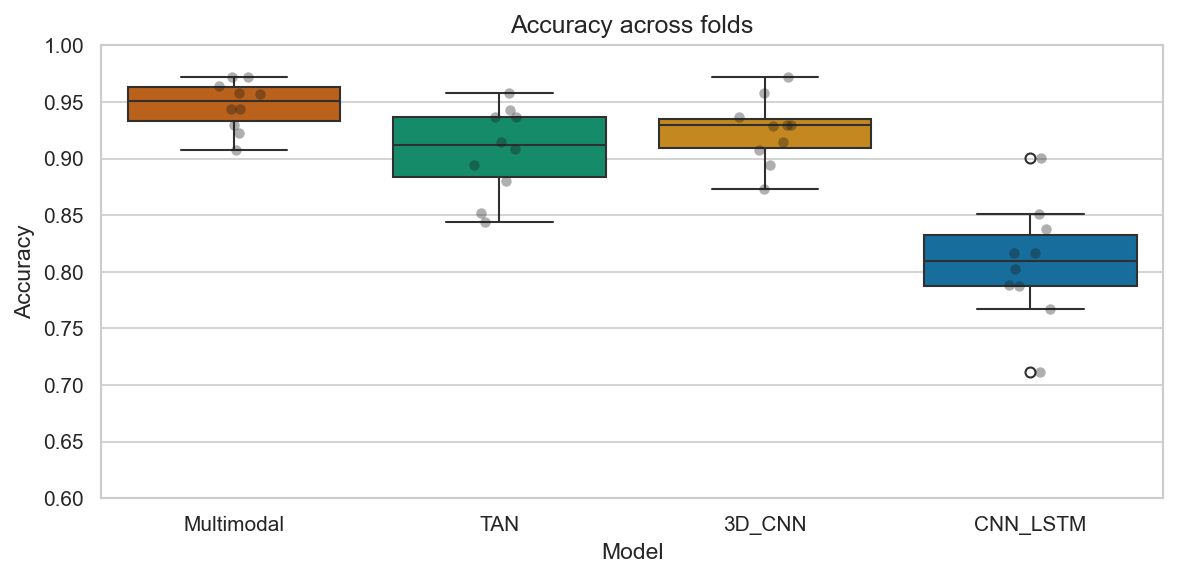

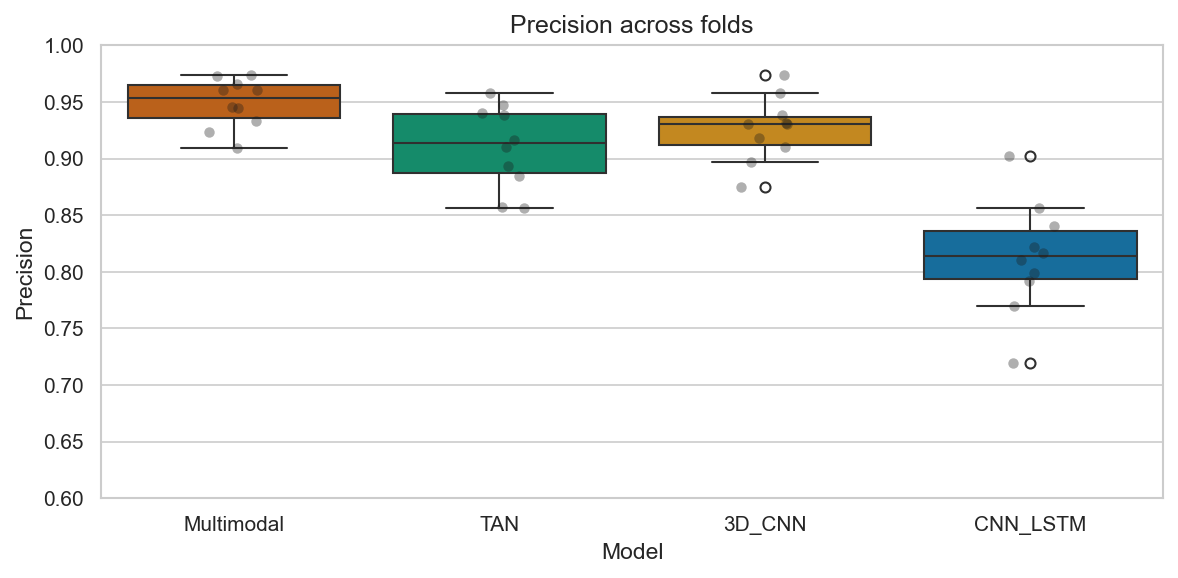

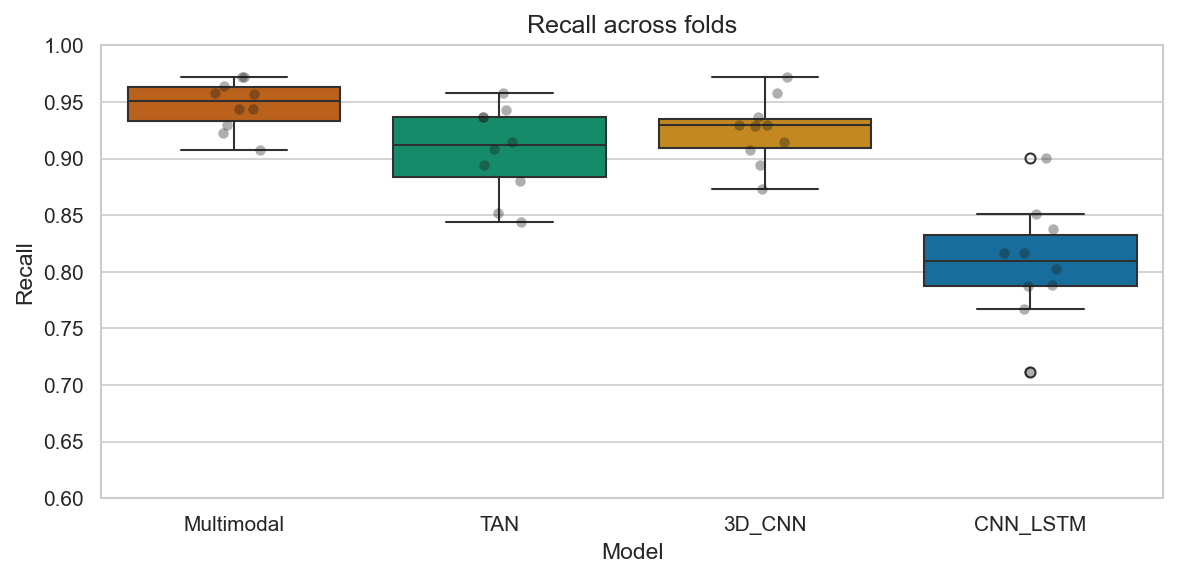

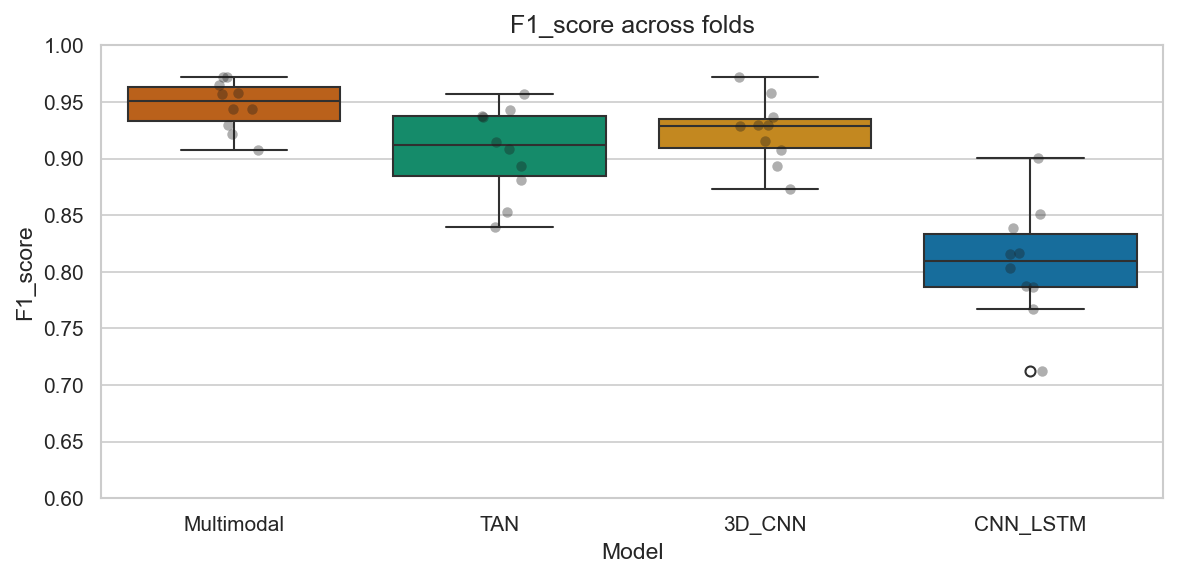

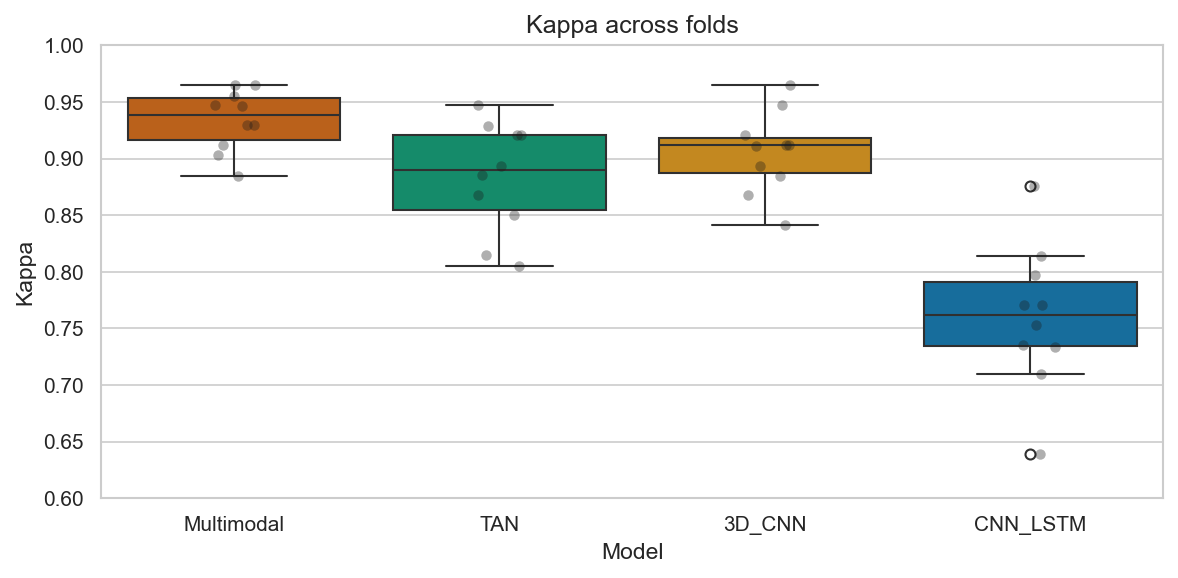

In [16]:
# Per-metric boxplots (publication style)

metrics = ['accuracy','precision','recall','f1_score','kappa']
for metric in metrics:
    fig, ax = plt.subplots(figsize=(8,4))
    sns.boxplot(data=df, x='model_name', y=metric, palette=COLORS, ax=ax)
    sns.stripplot(data=df, x='model_name', y=metric, color='k', alpha=0.35, ax=ax)
    ax.set_ylim(0.6, 1.0)
    finalize(ax, title=f'{metric.capitalize()} across folds', xlabel='Model', ylabel=metric.capitalize(), fname=f'box_{metric}.png')

In [17]:
from scipy.stats import wilcoxon

,m1,m2,wilcoxon_stat,p_uncorrected,mean_diff,holm_threshold,reject_h0
0,3D_CNN,CNN_LSTM,0.0,0.001953,0.116347,0.008333,True
1,CNN_LSTM,Multimodal,0.0,0.001953,-0.138937,0.010000,True
2,CNN_LSTM,TAN,1.0,0.003906,-0.098706,0.012500,True
3,Multimodal,TAN,2.0,0.005859,0.040231,0.016667,True
4,3D_CNN,Multimodal,10.0,0.138641,-0.022590,0.025000,False
5,3D_CNN,TAN,15.0,0.232422,0.017641,0.050000,False


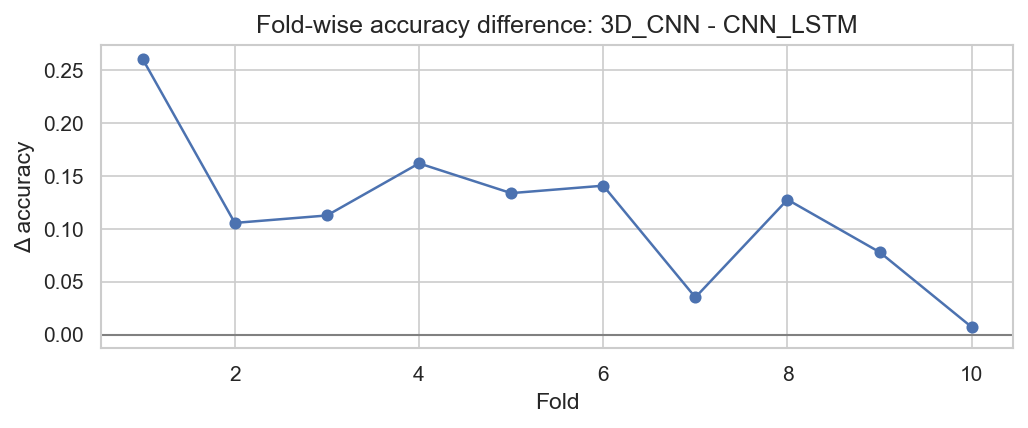

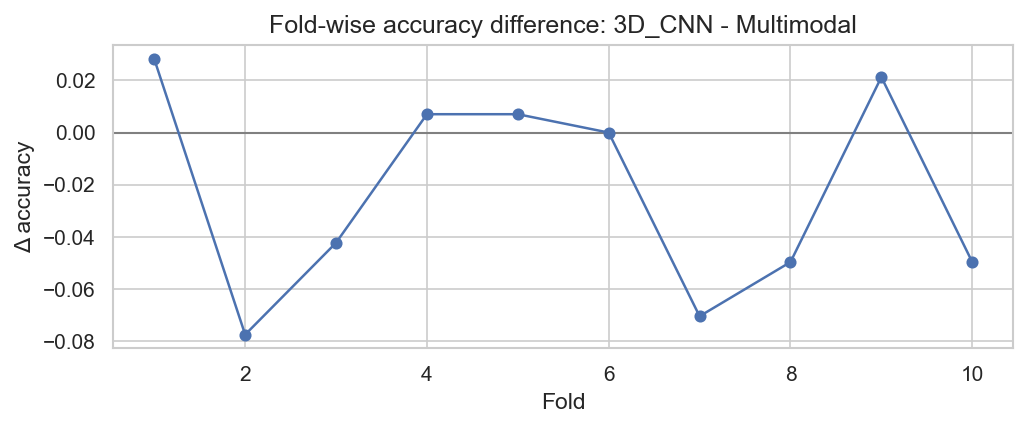

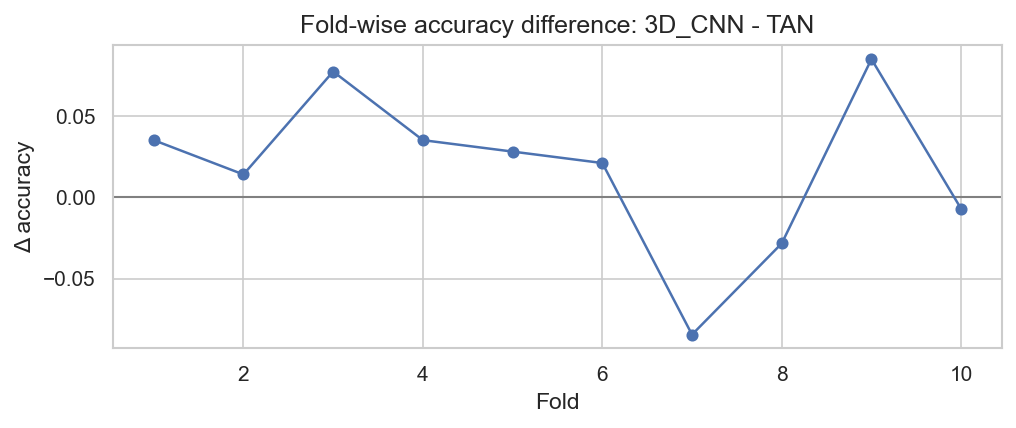

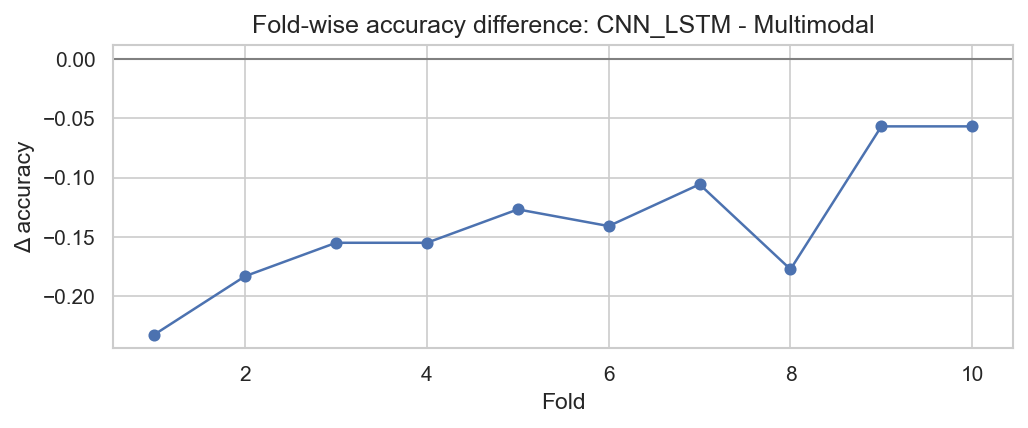

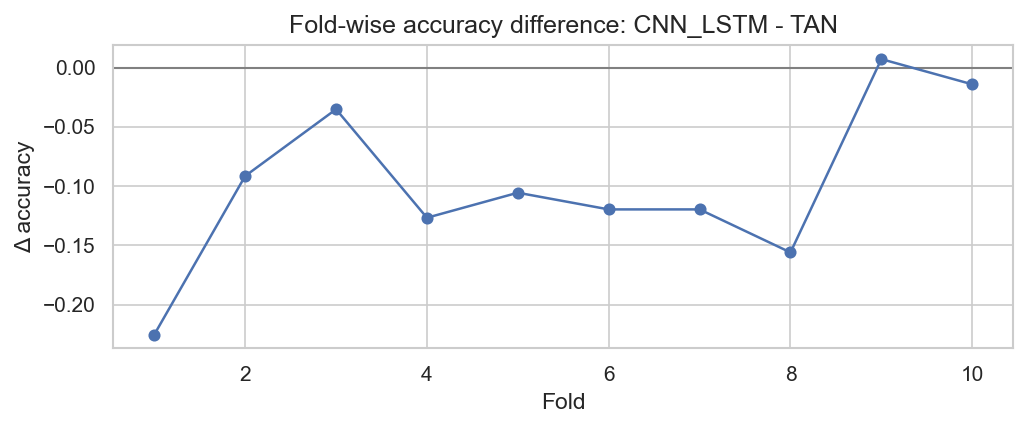

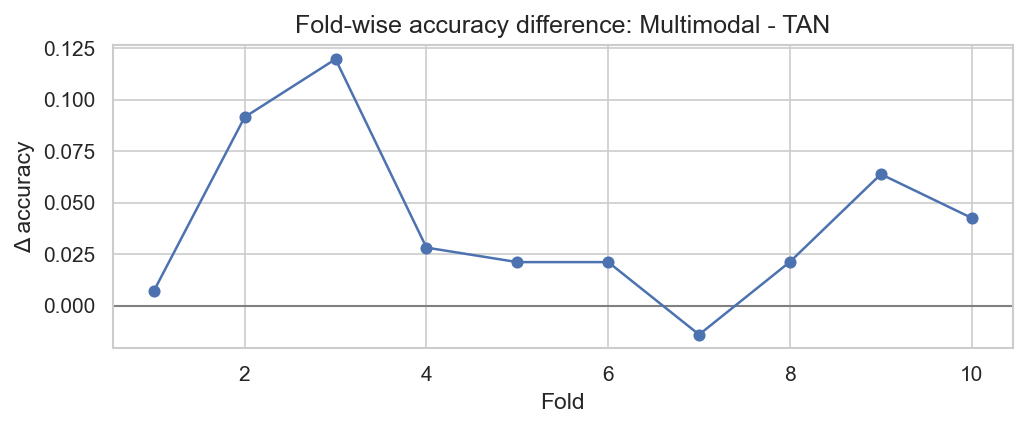

In [18]:
# Pairwise fold-wise differences and Wilcoxon signed-rank tests
pairs = list(it.combinations(sorted(df['model_name'].unique()), 2))
wilcox_rows = []

for m1, m2 in pairs:
    a = df[df.model_name==m1].sort_values('fold')['accuracy'].values
    b = df[df.model_name==m2].sort_values('fold')['accuracy'].values
    diff = a - b

    # Save difference plot
    fig, ax = plt.subplots(figsize=(7,3))
    ax.axhline(0, color='gray', lw=1)
    ax.plot(range(1, len(diff)+1), diff, marker='o')
    finalize(ax, title=f'Fold-wise accuracy difference: {m1} - {m2}', xlabel='Fold', ylabel='Δ accuracy', fname=f'diff_{m1}_vs_{m2}.png')
    # Wilcoxon
    try:
        stat, p = wilcoxon(a, b, zero_method='wilcox', alternative='two-sided')
    except ValueError:

        # fallback if all diffs are zero
        stat, p = (0.0, 1.0)
    wilcox_rows.append({'m1': m1, 'm2': m2, 'wilcoxon_stat': stat, 'p_uncorrected': p, 'mean_diff': diff.mean()})

wilcox_df = pd.DataFrame(wilcox_rows).sort_values('p_uncorrected').reset_index(drop=True)
K = len(wilcox_df)
wilcox_df['holm_threshold'] = [0.05/(K - i) for i in range(K)]
wilcox_df['reject_h0'] = wilcox_df['p_uncorrected'] < wilcox_df['holm_threshold']
wilcox_df.to_csv('../analysis/outputs/wilcoxon_accuracy.csv', index=False)
wilcox_df


Simple Nemenyi critical difference summary (values only)  
Average ranks per model from Friedman section  

In [19]:
ranks_file = '../analysis/outputs/friedman_avg_ranks.csv'
if Path(ranks_file).exists():
    ranks = pd.read_csv(ranks_file)
    ranks = ranks.rename(columns={ranks.columns[0]: 'model_name', ranks.columns[1]: 'avg_rank'})
    k = ranks.shape[0]
    n = df['fold'].nunique()
    # Critical difference for Nemenyi (q_alpha approximated for alpha=0.05): q≈2.569 (k up to ~10)
    q_alpha = 2.569
    cd = q_alpha * math.sqrt(k*(k+1)/(6*n))
    ranks = ranks.sort_values('avg_rank')
    ranks['avg_rank'] = ranks['avg_rank'].round(3)
    print('Average ranks (lower better):')
    display(ranks)
    print(f'Approximate critical difference (alpha=0.05): {cd:.3f}')
    with open('../analysis/outputs/nemenyi_cd.txt', 'w') as f:
        f.write('Average ranks (lower better)\n')
        f.write(ranks.to_csv(index=False))
        f.write(f'\nApproximate CD (alpha=0.05): {cd:.3f}\n')
else:
    print('Run Friedman cell first to produce ranks file.')


Average ranks (lower better):


,model_name,avg_rank
0,Multimodal,1.55
1,3D_CNN,1.85
2,TAN,2.70
3,CNN_LSTM,3.90


Approximate critical difference (alpha=0.05): 1.483


In [20]:
# Friedman test across models + Nemenyi critical difference (conceptual)

# Reshape to matrix (folds x models)
acc_mat = df.pivot_table(index='fold', columns='model_name', values='accuracy')
# Friedman (non-parametric repeated measures)
fr_stat, fr_p = friedmanchisquare(*[acc_mat[m].values for m in acc_mat.columns])
print('Friedman chi^2=%.3f, p=%.6f' % (fr_stat, fr_p))


Friedman chi^2=20.152, p=0.000158


In [21]:
# Average ranks per model (lower is better)
ranks_fr = acc_mat.rank(axis=1, ascending=False).mean(axis=0).sort_values()
ranks_fr.to_csv('../analysis/outputs/friedman_avg_ranks.csv')
ranks_fr

model_name
Multimodal    1.55
3D_CNN        1.85
TAN           2.70
CNN_LSTM      3.90
dtype: float64

In [22]:
# Bootstrap confidence intervals for metrics
rng = np.random.default_rng(2025)
B = 5000
ci_records = []
for model_name, g in df.groupby('model_name'):
    for metric in ['accuracy','precision','recall','f1_score','kappa']:
        x = g[metric].values
        n = len(x)
        boots = []
        for _ in range(B):
            idx = rng.integers(0, n, size=n)
            boots.append(np.mean(x[idx]))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        ci_records.append({'model_name': model_name, 'metric': metric, 'mean': x.mean(), 'ci_lo': lo, 'ci_hi': hi})
ci_df = pd.DataFrame(ci_records)
ci_df.to_csv('../analysis/outputs/bootstrap_ci.csv', index=False)
ci_df.head()


,model_name,metric,mean,ci_lo,ci_hi
0,3D_CNN,accuracy,0.924473,0.908201,0.941424
1,3D_CNN,precision,0.926300,0.909602,0.943266
2,3D_CNN,recall,0.924473,0.907383,0.941325
3,3D_CNN,f1_score,0.924301,0.907291,0.940697
4,3D_CNN,kappa,0.905585,0.883718,0.926845


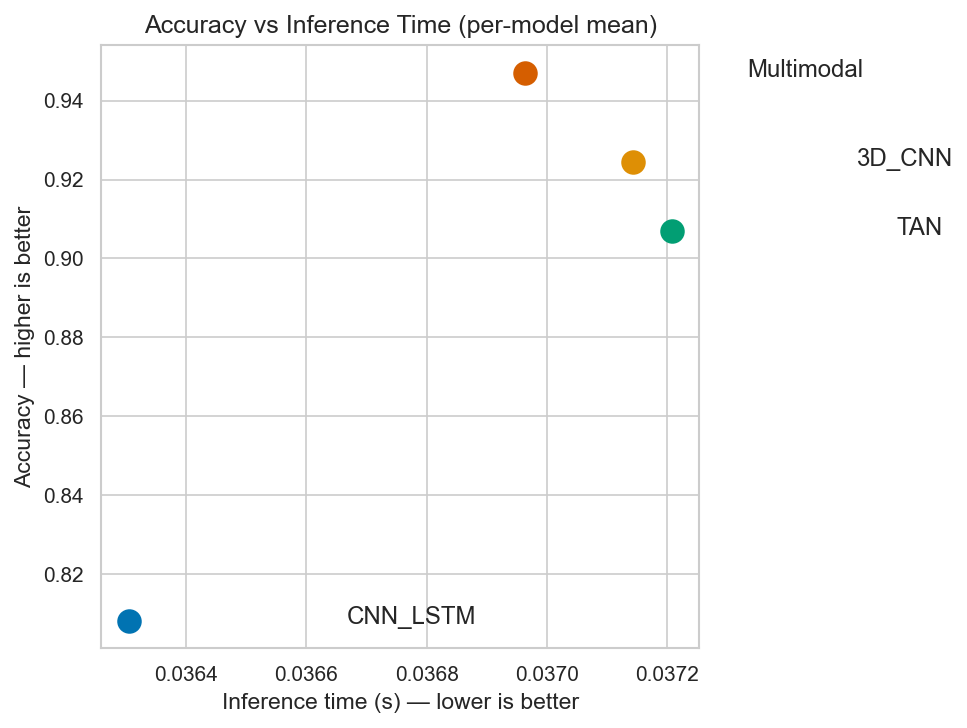

In [23]:
# Efficiency analysis: accuracy vs inference_time (Pareto frontier)
agg = df.groupby('model_name').agg({
    'accuracy':'mean','inference_time':'mean','training_time':'mean'
}).reset_index()

plt.figure(figsize=(7,5))
for m, row in agg.set_index('model_name').iterrows():
    plt.scatter(row['inference_time'], row['accuracy'], s=120, label=m, color=COLORS.get(m, '#555'))
    plt.text(row['inference_time']*1.01, row['accuracy']*0.999, m)
plt.xlabel('Inference time (s) — lower is better')
plt.ylabel('Accuracy — higher is better')
plt.title('Accuracy vs Inference Time (per-model mean)')
plt.tight_layout()
plt.savefig('../analysis/figures/accuracy_vs_inference.png', dpi=200)
plt.show()

In [24]:
# Identify Pareto-efficient points
pts = agg[['inference_time','accuracy']].values
is_efficient = np.ones(pts.shape[0], dtype=bool)
for i, (t1, a1) in enumerate(pts):
    if not is_efficient[i]:
        continue
    dominates = (pts[:,0] <= t1) & (pts[:,1] >= a1)
    dominates[i] = False
    is_efficient[dominates] = False
agg['pareto_efficient'] = is_efficient
agg.to_csv('../analysis/outputs/efficiency_pareto.csv', index=False)
agg

,model_name,accuracy,inference_time,training_time,pareto_efficient
0,3D_CNN,0.924473,0.037143,2.149458,False
1,CNN_LSTM,0.808126,0.036304,1.812183,True
2,Multimodal,0.947063,0.036963,2.308219,False
3,TAN,0.906832,0.037208,2.255319,True
